# Question 2: Road Traffic Accident Severity

## Stage 5: Feature Engineering and Feature Selection

Group: Group 2

Members: Armand Ikirezi and Mariam Nyirarukundo

In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

project_dir = Path(r"D:\MYProject\ML_Element1")

cleaned_path = (
    project_dir
    / "q2_own_scenario"
    / "data"
    / "interim"
    / "q2_cleaned.csv"
)

df = pd.read_csv(cleaned_path)

display(df.head())


,accident_id,district,road_type,weather,road_surface,lighting,time_of_day,vehicle_type,speed_limit_kmh,vehicles_involved,road_users_affected,response_time_min,severity
0,RWACC-00001,Rusizi,Market road,Rain,Dry,Dark,Afternoon,Car,60.0,2,2,10.1,Serious
1,RWACC-00002,Karongi,Highway,Clear,Damaged,Daylight,Morning,Car,100.0,2,4,27.6,Serious
2,RWACC-00003,Rubavu,Highway,Clear,Gravel,Daylight,Morning,Car,50.0,1,1,19.5,Minor
3,RWACC-00004,Kicukiro,Urban,Clear,Wet,Dark,Evening,Bus,30.0,2,1,28.2,Serious
4,RWACC-00005,Rusizi,Market road,NaN,Dry,Dark,Night,Truck,40.0,1,2,9.2,Fatal


In [2]:

# Night accident
df["night_accident"] = (
    df["time_of_day"] == "Night"
).astype(int)

# Poor weather
df["poor_weather"] = (
    df["weather"].isin(["Rain", "Fog"])
).astype(int)

# Poor road surface
df["poor_surface"] = (
    df["road_surface"].isin(["Wet", "Damaged"])
).astype(int)

# Heavy vehicle involvement
df["high_risk_vehicle"] = (
    df["vehicle_type"].isin(["Bus", "Truck"])
).astype(int)

# Multiple vehicles
df["multi_vehicle"] = (
    df["vehicles_involved"] >= 2
).astype(int)

# Group affected road users
df["affected_users_group"] = pd.cut(
    df["road_users_affected"],
    bins=[0, 2, 4, 6],
    labels=["Low", "Medium", "High"]
)

display(
    df[
        [
            "time_of_day",
            "night_accident",
            "weather",
            "poor_weather",
            "road_surface",
            "poor_surface",
            "vehicle_type",
            "high_risk_vehicle",
            "vehicles_involved",
            "multi_vehicle",
            "road_users_affected",
            "affected_users_group"
        ]
    ].head(10)
)


,time_of_day,night_accident,weather,poor_weather,road_surface,poor_surface,vehicle_type,high_risk_vehicle,vehicles_involved,multi_vehicle,road_users_affected,affected_users_group
0,Afternoon,0,Rain,1,Dry,0,Car,0,2,1,2,Low
1,Morning,0,Clear,0,Damaged,1,Car,0,2,1,4,Medium
2,Morning,0,Clear,0,Gravel,0,Car,0,1,0,1,Low
3,Evening,0,Clear,0,Wet,1,Bus,1,2,1,1,Low
4,Night,1,NaN,0,Dry,0,Truck,1,1,0,2,Low
5,Afternoon,0,Clear,0,Dry,0,Car,0,1,0,1,Low
6,Afternoon,0,Clear,0,Wet,1,Motorcycle,0,1,0,2,Low
7,Afternoon,0,Rain,1,Dry,0,Motorcycle,0,1,0,2,Low
8,Morning,0,Fog,1,Dry,0,Motorcycle,0,2,1,6,High
9,Afternoon,0,Clear,0,Dry,0,Motorcycle,0,2,1,3,Medium


In [3]:

feature_justification = pd.DataFrame([
    ["night_accident", "time_of_day", "Night indicator", "Represents nighttime conditions"],
    ["poor_weather", "weather", "Rain/Fog indicator", "Represents adverse weather"],
    ["poor_surface", "road_surface", "Wet/Damaged indicator", "Represents poor road surface"],
    ["high_risk_vehicle", "vehicle_type", "Bus/Truck indicator", "Represents heavy vehicle involvement"],
    ["multi_vehicle", "vehicles_involved", "2 or more indicator", "Represents multi-vehicle accidents"],
    ["affected_users_group", "road_users_affected", "Low/Medium/High groups", "Categorizes accident size"]
], columns=[
    "New_Feature",
    "Original_Feature",
    "Transformation",
    "Justification"
])

feature_justification.to_csv(
    project_dir
    / "q2_own_scenario"
    / "docs"
    / "feature_justification.csv",
    index=False
)

display(feature_justification)


,New_Feature,Original_Feature,Transformation,Justification
0,night_accident,time_of_day,Night indicator,Represents nighttime conditions
1,poor_weather,weather,Rain/Fog indicator,Represents adverse weather
2,poor_surface,road_surface,Wet/Damaged indicator,Represents poor road surface
3,high_risk_vehicle,vehicle_type,Bus/Truck indicator,Represents heavy vehicle involvement
4,multi_vehicle,vehicles_involved,2 or more indicator,Represents multi-vehicle accidents
5,affected_users_group,road_users_affected,Low/Medium/High groups,Categorizes accident size


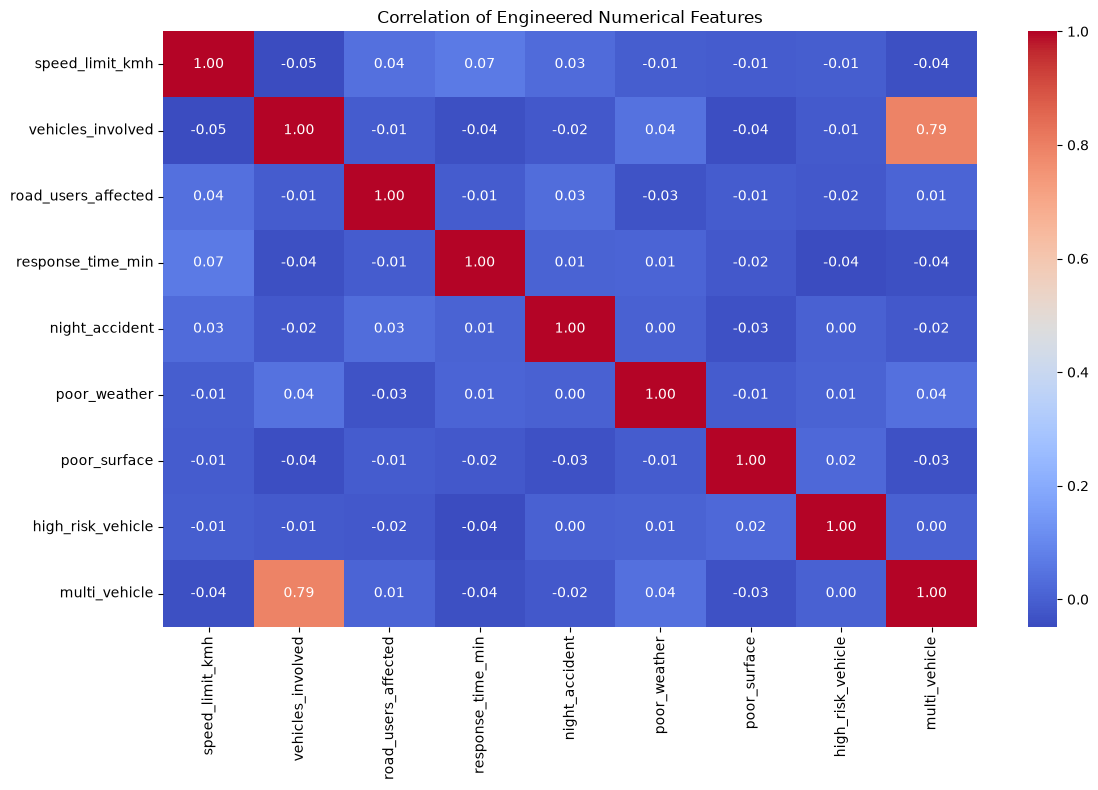

In [4]:

numeric_df = df.select_dtypes(
    include=["number"]
)

correlation = numeric_df.corr()

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation of Engineered Numerical Features")
plt.tight_layout()
plt.show()


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Exclude target and identifier
X = df.drop(columns=["severity", "accident_id"])
y = df["severity"]

# Recreate splits
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Feature groups
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

X_validation_processed = preprocessor.transform(
    X_validation
)

X_test_processed = preprocessor.transform(
    X_test
)

encoded_feature_names = preprocessor.get_feature_names_out()

# Mutual information selection
selector = SelectKBest(
    score_func=mutual_info_classif,
    k=min(10, X_train_processed.shape[1])
)

X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train
)

X_validation_selected = selector.transform(
    X_validation_processed
)

X_test_selected = selector.transform(
    X_test_processed
)

selected_features = encoded_feature_names[
    selector.get_support()
]

print("Selected features:")
print(selected_features)


Selected features:
['numeric__speed_limit_kmh' 'numeric__poor_weather'
 'numeric__poor_surface' 'numeric__high_risk_vehicle'
 'categorical__weather_Clear' 'categorical__weather_Fog'
 'categorical__weather_Rain' 'categorical__road_surface_Dry'
 'categorical__lighting_Dark' 'categorical__lighting_Daylight']


In [6]:

feature_scores = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Mutual_Information_Score": selector.scores_,
    "Selected": selector.get_support()
})

feature_scores = feature_scores.sort_values(
    "Mutual_Information_Score",
    ascending=False
)

display(feature_scores)

feature_scores.to_csv(
    project_dir
    / "q2_own_scenario"
    / "docs"
    / "feature_selection_scores.csv",
    index=False
)


,Feature,Mutual_Information_Score,Selected
25,categorical__weather_Clear,0.073726,True
5,numeric__poor_weather,0.050525,True
27,categorical__weather_Rain,0.046018,True
30,categorical__road_surface_Dry,0.044369,True
7,numeric__high_risk_vehicle,0.042885,True
33,categorical__lighting_Dark,0.039756,True
26,categorical__weather_Fog,0.039252,True
6,numeric__poor_surface,0.029193,True
0,numeric__speed_limit_kmh,0.027052,True
34,categorical__lighting_Daylight,0.026577,True


In [7]:

processed_dir = (
    project_dir
    / "q2_own_scenario"
    / "data"
    / "processed"
)

processed_dir.mkdir(parents=True, exist_ok=True)

selected_train = pd.DataFrame(
    X_train_selected,
    columns=selected_features
)

selected_train["severity"] = y_train.reset_index(
    drop=True
)

selected_validation = pd.DataFrame(
    X_validation_selected,
    columns=selected_features
)

selected_validation["severity"] = (
    y_validation.reset_index(drop=True)
)

selected_test = pd.DataFrame(
    X_test_selected,
    columns=selected_features
)

selected_test["severity"] = y_test.reset_index(
    drop=True
)

selected_train.to_csv(
    processed_dir / "q2_train_selected.csv",
    index=False
)

selected_validation.to_csv(
    processed_dir / "q2_validation_selected.csv",
    index=False
)

selected_test.to_csv(
    processed_dir / "q2_test_selected.csv",
    index=False
)

print("Selected datasets saved.")


Selected datasets saved.
